# 01. Análise exploratória do IDRiD (segmentação)

Gerado a partir de `scripts/eda_stats.py` e `scripts/eda_figures.py`. Frações calculadas sobre o campo de visão (FOV) da retina.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.read_csv('../results/eda/resumo_por_classe.csv', index_col=0)

,imagens,frac_fov_media_pct,componentes_mediana,componentes_total,area_mediana_px,area_max_px,pct_dos_pixels_de_lesao
cls,,,,,,,
MA,81,0.150,35.0,3497,234.0,2231,4.722
HE,80,1.483,17.5,1900,1607.5,1256545,45.974
EX,81,1.301,82.0,11642,217.0,376764,40.836
SE,40,0.547,3.0,150,8653.0,60776,8.468


## Fração de pixels por classe
MA ocupa ~0,15% do FOV; HE e EX ~1,3-1,5%; SE ~0,5%. Por pixel, HE (46%) e EX (41%) dominam o total de pixels de lesão, enquanto MA representa só ~5%.

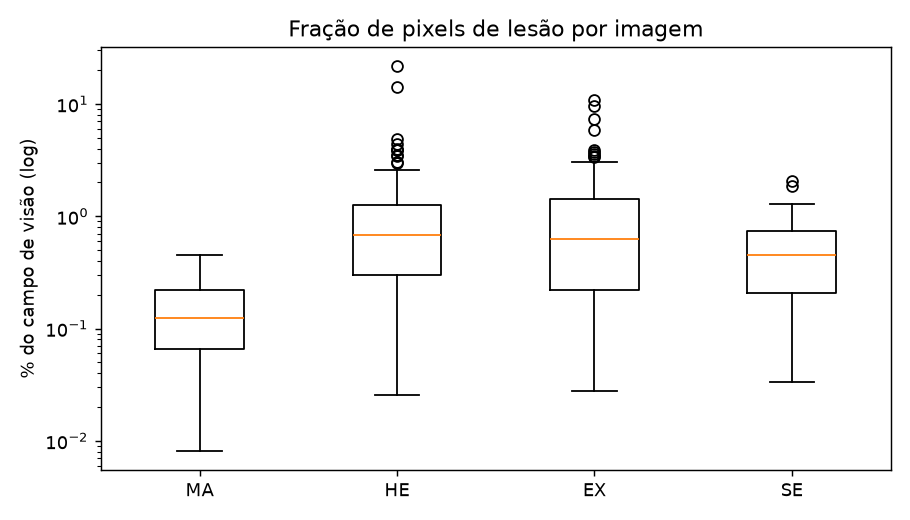

In [2]:
display(Image('../results/eda/frac_pixels_por_classe.png'))

## Tamanho e número de lesões
MA e EX são numerosos e pequenos (mediana ~220-230 px); HE e SE são maiores e menos frequentes. SE tem só 150 componentes em 40 imagens.

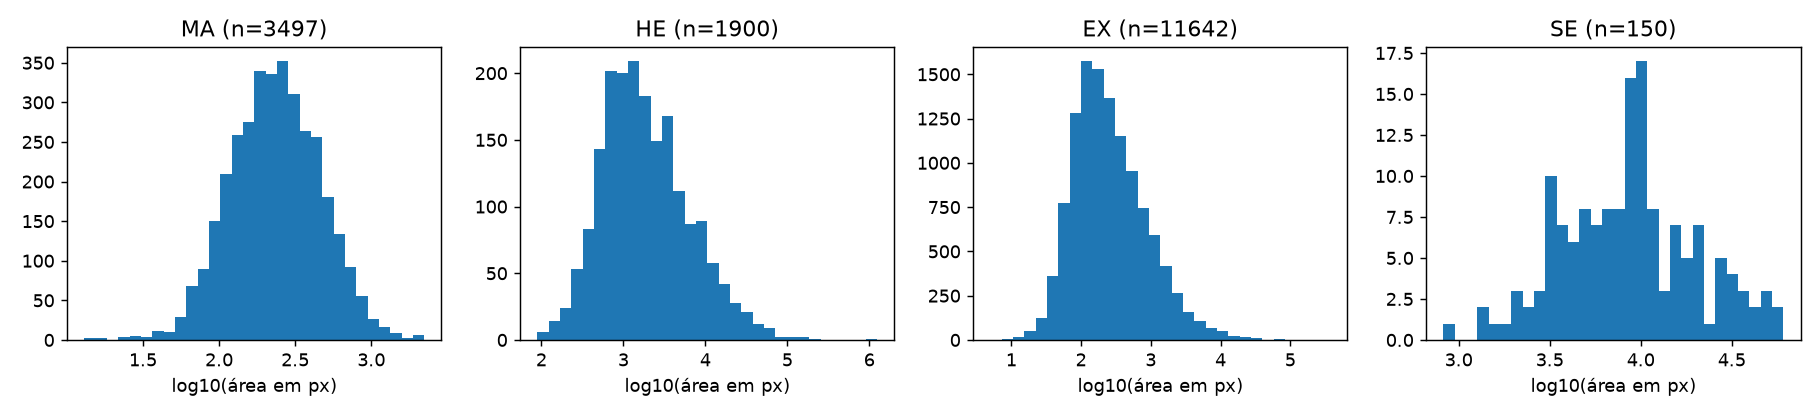

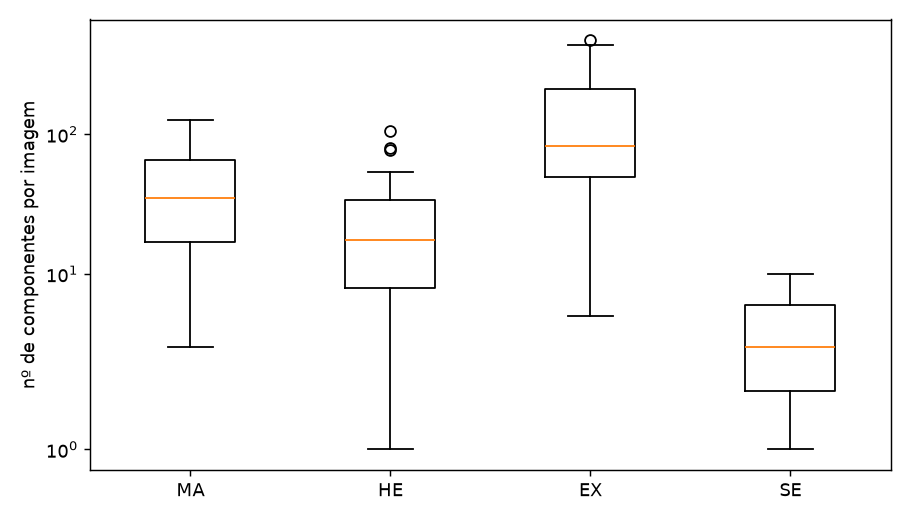

In [3]:
display(Image('../results/eda/tamanho_componentes.png'))
display(Image('../results/eda/componentes_por_imagem.png'))

## Exemplos com máscaras sobrepostas
Inclui imagens sem a máscara de HE/SE (IDRiD_43) para lembrar que ausência de arquivo não é ausência de lesão.

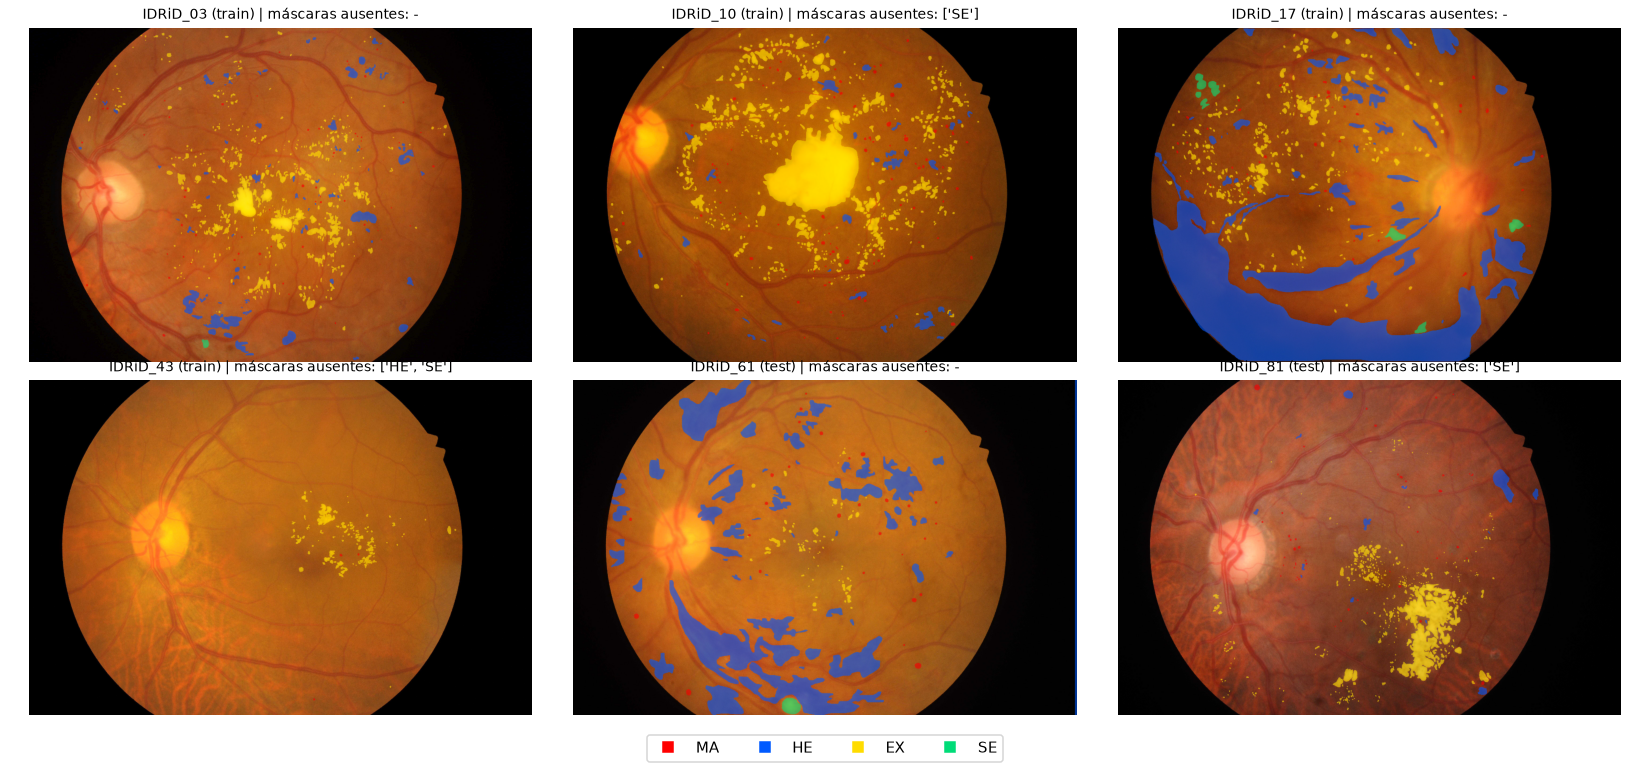

In [4]:
display(Image('../results/eda/overlay_exemplos.png'))

## Observações para a modelagem
- Desbalanceamento forte: MA tem ~10x menos pixels que HE/EX. Considerar pesos por classe ou Dice na loss.
- MA exige resolução alta: lesões de 13 a ~2200 px (mediana ~230 px) na resolução original de 2848×4288; reduzir demais as apaga.
- Há imagens com lesões enormes (ex.: HE em IDRiD_17, 1,26 M px): patches de 512×512 podem cortar essas regiões.
- SE existe em só 40 imagens, então a perda mascarada é essencial.
- Dado atípico: `IDRiD_81_EX.tif` é BGRA (canal alfa = 255 em todos os pixels, lesão no canal vermelho). O carregador descarta o alfa; sem isso a máscara viraria a imagem inteira.